In [9]:
# Загрузка датасета "Рынок недвижимости Ames" через Google Drive
!pip install gdown -q
import gdown

file_id = '1vOMckuYgfqwNMvnvec5MxRaecAgDfTMJ'

# Скачиваем файл train.csv
gdown.download(f'https://drive.google.com/uc?id={file_id}', 'train.csv', quiet=False)

print("\n✅ Файл train.csv успешно загружен!")

Downloading...
From: https://drive.google.com/uc?id=1vOMckuYgfqwNMvnvec5MxRaecAgDfTMJ
To: /content/train.csv
100%|██████████| 461k/461k [00:00<00:00, 80.7MB/s]


✅ Файл train.csv успешно загружен!


In [10]:
# Импортируем библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем данные
df = pd.read_csv('train.csv')

# Смотрим первые 5 строк
print("=== Первые 5 строк данных ===")
display(df.head())

=== Первые 5 строк данных ===


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [11]:
# Общая информация о данных
print("\n=== Информация о данных ===")
df.info()

# Поиск пропущенных значений
print("\n=== Количество пропусков ===")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Поиск дублирующих значений
print("\n=== Проверка дубликатов ===")
print(f"Количество дубликатов: {df.duplicated().sum()}")


=== Информация о данных ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non

In [12]:
# ==========================================
# ПРОВЕРКА: Действительно ли у домов с пропуском в GarageYrBlt нет гаража?
# ==========================================

# 1. Находим все строки, где год постройки гаража НЕ указан (исходные пропуски)
houses_no_garage_year = df[df['GarageYrBlt'].isna()]

print(f"🔍 Всего домов с пропуском в 'GarageYrBlt': {len(houses_no_garage_year)}")
print('Гипотеза: у домов с пропуском в GarageYrBlt нет гаража')

# 2. Проверяем характеристики гаража у этих конкретных домов
print("\n--- Анализ характеристик гаража у этих домов ---")
print(f"• У скольких из них GarageCars (вместимость) == 0? : {(houses_no_garage_year['GarageCars'] == 0).sum()}")
print(f"• У скольких из них GarageArea (площадь) == 0?   : {(houses_no_garage_year['GarageArea'] == 0).sum()}")
print(f"• У скольких из них GarageType (тип) == NaN?     : {(houses_no_garage_year['GarageType'].isna()).sum()}")

# 3. Ищем ИСКЛЮЧЕНИЯ: дома, где год не указан, НО гараж физически есть (площадь или вместимость > 0)
exceptions = houses_no_garage_year[
    (houses_no_garage_year['GarageCars'] > 0) |
    (houses_no_garage_year['GarageArea'] > 0)
]

print(f"\n⚠️ Найдено исключений (гараж есть, но год не указан): {len(exceptions)}")

# 4. Делаем окончательный вывод
if len(exceptions) == 0:
    print("\nГИПОТЕЗА ПОДТВЕРЖДЕНА! ✅")
    print("Все дома без указанного года постройки гаража действительно НЕ ИМЕЮТ гаража \n(площадь и вместимость равны 0).")
    print("👉 Вывод: Заполнение пропусков значением 0 абсолютно безопасно и логически верно!")
else:
    print("\n❌ Внимание: Обнаружены аномалии!")
    print("Следующие дома имеют гараж, но год его постройки не указан:")
    display(exceptions[['GarageType', 'GarageCars', 'GarageArea', 'GarageYrBlt']])
    print("👉 Вывод: Для этих исключений нужно заполнить год медианой, а не нулем.")

🔍 Всего домов с пропуском в 'GarageYrBlt': 81
Гипотеза: у домов с пропуском в GarageYrBlt нет гаража

--- Анализ характеристик гаража у этих домов ---
• У скольких из них GarageCars (вместимость) == 0? : 81
• У скольких из них GarageArea (площадь) == 0?   : 81
• У скольких из них GarageType (тип) == NaN?     : 81

⚠️ Найдено исключений (гараж есть, но год не указан): 0

ГИПОТЕЗА ПОДТВЕРЖДЕНА! ✅
Все дома без указанного года постройки гаража действительно НЕ ИМЕЮТ гаража 
(площадь и вместимость равны 0).
👉 Вывод: Заполнение пропусков значением 0 абсолютно безопасно и логически верно!


In [13]:
# Заполняем пропуски для признаков, где "нет" = отсутствие объекта
cols_with_na = ['Alley', 'PoolQC', 'Fence', 'MiscFeature', 'FireplaceQu',
                'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

for col in cols_with_na:
    df[col] = df[col].fillna('None')

# Проверка пропусков после обработки
print("✅ Заполнили 'None' те пропущенные значения, где отсутствие признака = отсутствие объекта\nПропуски после обработки:")
print(df.isnull().sum()[df.isnull().sum() > 0])


✅ Заполнили 'None' те пропущенные значения, где отсутствие признака = отсутствие объекта
Пропуски после обработки:
LotFrontage    259
MasVnrType     872
MasVnrArea       8
Electrical       1
GarageYrBlt     81
dtype: int64


In [14]:
# ОБРАБОТКА ОСТАВШИХСЯ ПРОПУСКОВ

print('=== Обработка оставшихся пропусков ===')

# 1. LotFrontage (длина участка у улицы) - числовой признак
# Заполняем медианой (более устойчива к выбросам, чем среднее)
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
print(f"LotFrontage: заполнили медианой {df['LotFrontage'].median():.1f}")

# 2. MasVnrType (тип каменной кладки) - категориальный признак
# Так как много пропусков (59.7%), скорее всего это означает "нет каменной кладки"
df['MasVnrType'] = df['MasVnrType'].fillna('None')
print(f"MasVnrType: заполнили значением 'None'")

# 3. MasVnrArea (площадь каменной кладки) - числовой признак
# Если типа кладки нет, то и площадь = 0
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
print(f"MasVnrArea: заполнили нулем")

# 4. Electrical (электричество) - категориальный признак
# Всего 1 пропуск - заполним самым частым значением (модой)
most_common_electrical = df['Electrical'].mode()[0]
df['Electrical'] = df['Electrical'].fillna(most_common_electrical)
print(f"Electrical: заполнили модой '{most_common_electrical}'")

# 5. GarageYrBlt (год постройки гаража) - числовой признак
# Ставим 0, если гаража нет (это безопасно,
# т.к. отсутствие гаража явно закодировано в GarageCars = 0 и GarageArea = 0)
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)
# Или можно заполнить годом постройки дома (если гараж был построен вместе с домом)
# df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
print(f"GarageYrBlt: заполнили нулем (нет гаража), тип данных остался числовым")

# Меняем тип данных в признаке "год постройки гаража" на целочисленный
# для корректного отображения данных в BI-инструментах
df['GarageYrBlt'] = df['GarageYrBlt'].astype(int)

# ПРОВЕРКА РЕЗУЛЬТАТА
print("\n=== ИТОГОВАЯ ПРОВЕРКА ПРОПУСКОВ ===")

remaining = df.isnull().sum()[df.isnull().sum() > 0]

if len(remaining) == 0:
    print("✅ ВСЕ ПРОПУСКИ ОБРАБОТАНЫ!")
else:
    print("⚠️ Остались пропуски:")
    print(remaining)

print(f"\nОбщий размер данных: {df.shape[0]} строк, {df.shape[1]} столбцов")

# Сохраняем очищенный датасет
df_clean = df.copy()
print(f"Очищенные данные сохранены в df_clean")

# Экспорт очищенного датасета
df_clean.to_csv('house_prices_clean.csv', index=False)
print("✅ Файл сохранен для загрузки в DataLens")

=== Обработка оставшихся пропусков ===
LotFrontage: заполнили медианой 69.0
MasVnrType: заполнили значением 'None'
MasVnrArea: заполнили нулем
Electrical: заполнили модой 'SBrkr'
GarageYrBlt: заполнили нулем (нет гаража), тип данных остался числовым

=== ИТОГОВАЯ ПРОВЕРКА ПРОПУСКОВ ===
✅ ВСЕ ПРОПУСКИ ОБРАБОТАНЫ!

Общий размер данных: 1460 строк, 81 столбцов
Очищенные данные сохранены в df_clean
✅ Файл сохранен для загрузки в DataLens


In [15]:
# ЭКСПОРТ ДАТАСЕТА В GOOGLE DRIVE

from google.colab import drive

# Монтируем Google Drive (force_remount=False, чтобы не перемонтировать при повторном запуске)
drive.mount('/content/drive')

# Сохраняем очищенный датасет
drive_file_path = '/content/drive/MyDrive/house_prices_clean.csv'
df_clean.to_csv(drive_file_path, index=False)

print(f"✅ Датасет сохранён в Google Drive:")
print(f"   Путь: {drive_file_path}")
print(f"   Строк: {df_clean.shape[0]}, столбцов: {df_clean.shape[1]}")

Mounted at /content/drive
✅ Датасет сохранён в Google Drive:
   Путь: /content/drive/MyDrive/house_prices_clean.csv
   Строк: 1460, столбцов: 81


In [16]:
# Статистическое описание числовых признаков
print("\n=== Описание числовых признаков ===")
display(df_clean.describe())

# Описание категориальных признаков
print("\n=== Описание категориальных признаков ===")
display(df_clean.describe(include=['object']))

# Проверяем размерность данных
print(f"\nРазмер данных: {df_clean.shape[0]} строк и {df_clean.shape[1]} столбцов")


=== Описание числовых признаков ===


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,69.863699,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.117123,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,22.027677,9981.264932,1.382997,1.112799,30.202904,20.645407,180.731373,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,60.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,79.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,164.250000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



=== Описание категориальных признаков ===


,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,...,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460
unique,5,2,3,4,4,2,5,3,25,9,...,7,4,6,6,3,4,5,5,9,6
top,RL,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,None,None,None,WD,Normal
freq,1151,1454,1369,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,1453,1179,1406,1267,1198



Размер данных: 1460 строк и 81 столбцов


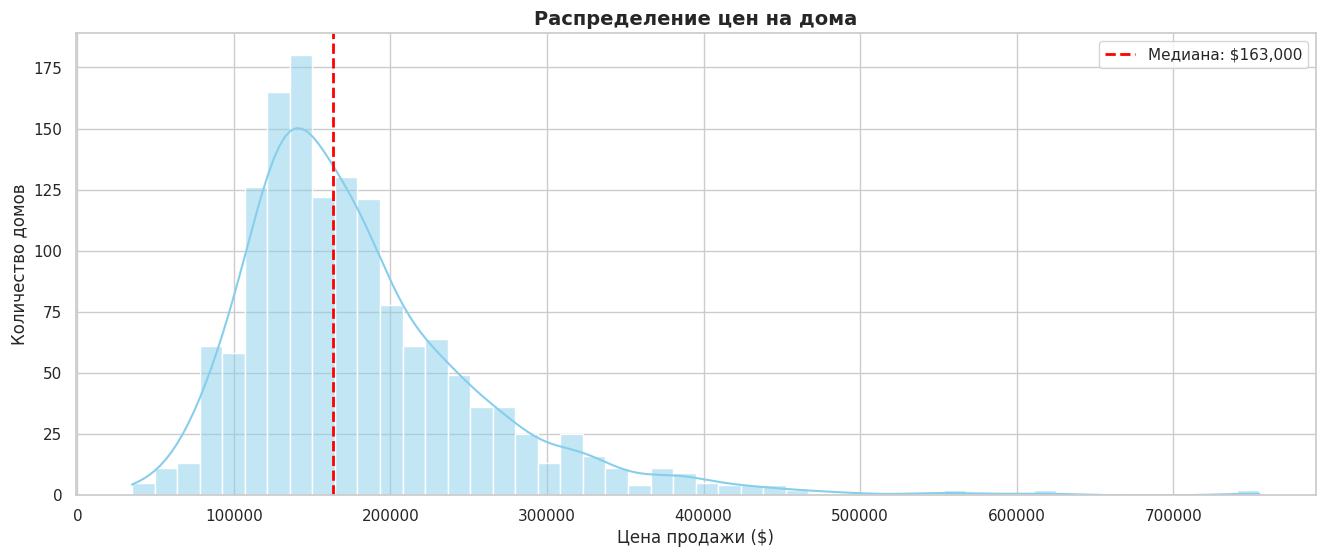

In [17]:
# ЭТАП EDA: гистограмма распределения цен

# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (16, 6)


fig, ax = plt.subplots(figsize=(16, 6))

# === Распределение цен (гистограмма) ===
sns.histplot(df_clean['SalePrice'], kde=True, color='skyblue', bins=50)
ax.set_title('Распределение цен на дома', fontsize=14, fontweight='bold')
ax.set_xlabel('Цена продажи ($)', fontsize=12)
ax.set_ylabel('Количество домов', fontsize=12)

# Добавляем вертикальную линию медианы
median_price = df_clean['SalePrice'].median()
ax.axvline(median_price, color='red', linestyle='--', linewidth=2,
                label=f'Медиана: ${median_price:,.0f}')
ax.legend()


Гипотеза №1: "Жилая площадь дома сильно влияет на цену продажи



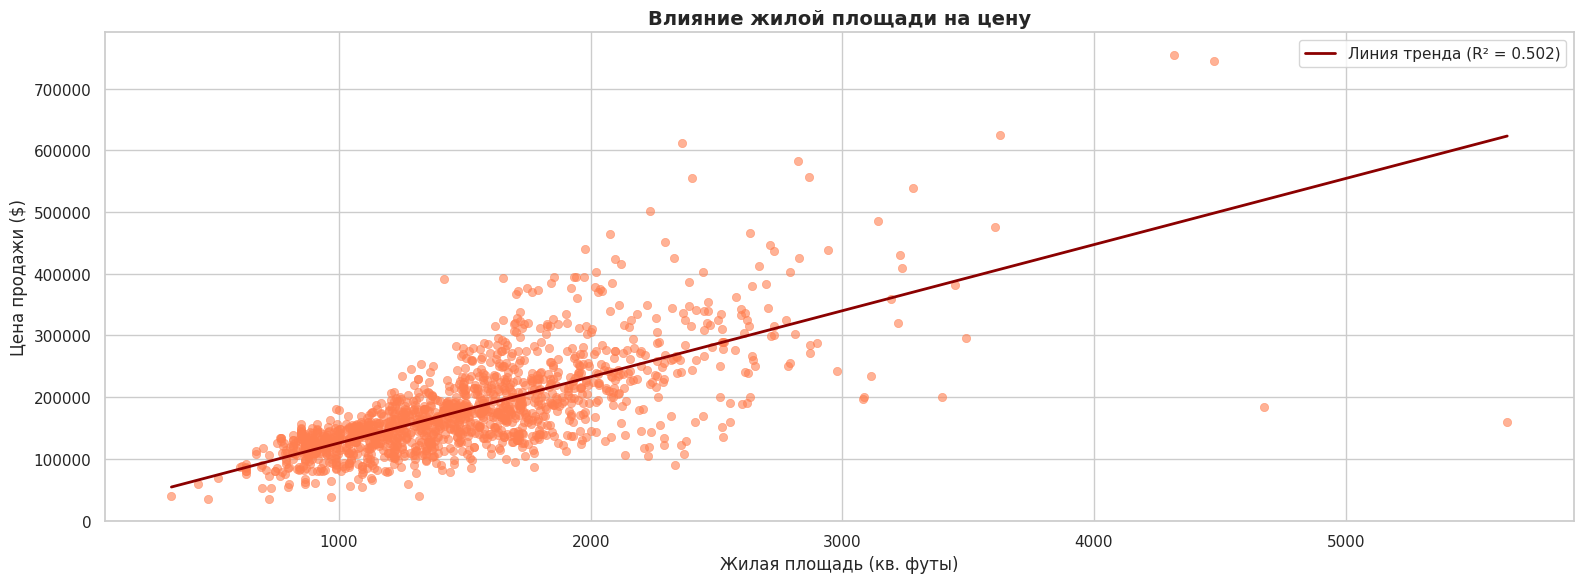


 Статистический анализ:
• Коэффициент корреляции Пирсона: 0.709
• Коэффициент детерминации R²: 0.502
• Медианная цена дома: $163,000
• Средняя жилая площадь: 1515 кв. футов

ВЫВОД: гипотеза подтверждена ✅
Наблюдается СИЛЬНАЯ положительная связь (r = 0.709).
Жилая площадь объясняет 50.2% вариации цен.
Чем больше площадь дома, тем выше его цена.


In [18]:
# Проверка Гипотезы №1:
# "Жилая площадь дома сильно влияет на цену продажи"

print('Гипотеза №1: "Жилая площадь дома сильно влияет на цену продажи\n')

# === Scatter plot площади vs цены ===

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (16, 6)

fig, ax = plt.subplots(figsize=(16, 6))

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df_clean,
                alpha=0.6, color='coral', edgecolor=None, ax=ax)
ax.set_title('Влияние жилой площади на цену', fontsize=14, fontweight='bold')
ax.set_xlabel('Жилая площадь (кв. футы)', fontsize=12)
ax.set_ylabel('Цена продажи ($)', fontsize=12)

# Добавляем линию тренда
from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(
    df_clean['GrLivArea'], df_clean['SalePrice'])
x_line = np.linspace(df_clean['GrLivArea'].min(), df_clean['GrLivArea'].max(), 100)
y_line = slope * x_line + intercept
ax.plot(x_line, y_line, color='darkred', linewidth=2,
        label=f'Линия тренда (R² = {r_value**2:.3f})')
ax.legend()

plt.tight_layout()
plt.show()

# === ЧИСЛОВОЕ ПОДТВЕРЖДЕНИЕ ГИПОТЕЗЫ ===
correlation = df_clean['GrLivArea'].corr(df_clean['SalePrice'])
print(f"\n Статистический анализ:")
print(f"• Коэффициент корреляции Пирсона: {correlation:.3f}")
print(f"• Коэффициент детерминации R²: {correlation**2:.3f}")
print(f"• Медианная цена дома: ${median_price:,.0f}")
print(f"• Средняя жилая площадь: {df_clean['GrLivArea'].mean():.0f} кв. футов")


if correlation > 0.6:
    print("\nВЫВОД: гипотеза подтверждена ✅")
    print(f"Наблюдается СИЛЬНАЯ положительная связь (r = {correlation:.3f}).")
    print(f"Жилая площадь объясняет {correlation**2*100:.1f}% вариации цен.")
    print("Чем больше площадь дома, тем выше его цена.")
elif correlation > 0.3:
    print("⚠️ ВЫВОД: Гипотеза подтверждена частично.")
    print(f"Связь умеренная (r = {correlation:.3f}).")
else:
    print("❌ ВЫВОД: Гипотеза не подтверждена.")
    print(f"Связь слабая (r = {correlation:.3f}).")

Гипотеза №1: "Дома в определенных районах стоят значительно дороже



/tmp/ipykernel_2483/821551734.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


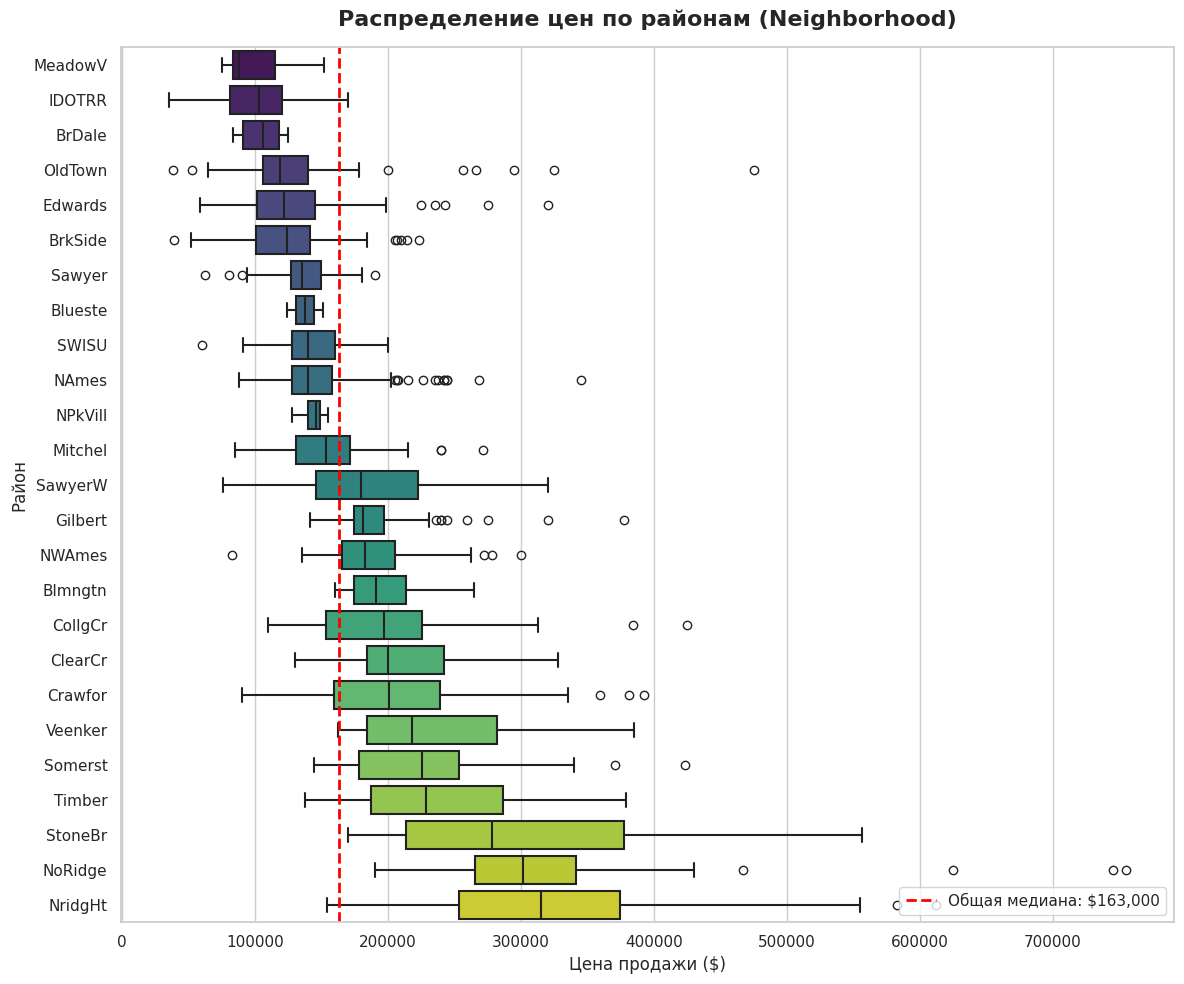


📊 Статистический анализ по районам:
• Всего уникальных районов в датасете: 25
• Общая медианная цена по всем районам: $163,000

🏆 ТОП-3 самых дорогих района (по медиане):
  1. StoneBr: $278,000
  2. NoRidge: $301,500
  3. NridgHt: $315,000

💰 ТОП-3 самых доступных района (по медиане):
  1. MeadowV: $88,000
  2. IDOTRR: $103,000
  3. BrDale: $106,000

ВЫВОД: гипотеза подтверждена ✅
Разница в медианной цене между самым дорогим (NridgHt) и самым дешевым (MeadowV) районом составляет более чем в 3 раз.
Локация (Neighborhood) является критически важным фактором ценообразования.


In [19]:
# Проверка Гипотезы №2
# "Дома в определенных районах стоят значительно дороже"

print('Гипотеза №1: "Дома в определенных районах стоят значительно дороже\n')

# 1. Вычисляем медианную цену для каждого района и сортируем для красивого графика
neighborhood_median_price = df_clean.groupby('Neighborhood')['SalePrice'].median().sort_values()

# 2. Настраиваем размер графика (горизонтальный формат лучше читается)
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# 3. Строим горизонтальный boxplot
sns.boxplot(
    x='SalePrice',
    y='Neighborhood',
    data=df_clean,
    order=neighborhood_median_price.index, # Сортируем по медиане
    palette='viridis',
    linewidth=1.5
)

# 4. Оформляем график
plt.title('Распределение цен по районам (Neighborhood)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Цена продажи ($)', fontsize=12)
plt.ylabel('Район', fontsize=12)

# Добавляем вертикальную линию общей медианы для сравнения
overall_median = df_clean['SalePrice'].median()
plt.axvline(overall_median, color='red', linestyle='--', linewidth=2,
            label=f'Общая медиана: ${overall_median:,.0f}')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

# === ЧИСЛОВОЕ ПОДТВЕРЖДЕНИЕ ===
top_3_expensive = neighborhood_median_price.tail(3).index.tolist()
top_3_prices = neighborhood_median_price.tail(3).values
bottom_3_cheap = neighborhood_median_price.head(3).index.tolist()
bottom_3_prices = neighborhood_median_price.head(3).values

print("\n📊 Статистический анализ по районам:")
print(f"• Всего уникальных районов в датасете: {df_clean['Neighborhood'].nunique()}")
print(f"• Общая медианная цена по всем районам: ${overall_median:,.0f}")
print(f"\n🏆 ТОП-3 самых дорогих района (по медиане):")
for i in range(3):
    print(f"  {i+1}. {top_3_expensive[i]}: ${top_3_prices[i]:,.0f}")
print(f"\n💰 ТОП-3 самых доступных района (по медиане):")
for i in range(3):
    print(f"  {i+1}. {bottom_3_cheap[i]}: ${bottom_3_prices[i]:,.0f}")

print("\nВЫВОД: гипотеза подтверждена ✅")
print(f"Разница в медианной цене между самым дорогим ({top_3_expensive[2]}) и самым дешевым ({bottom_3_cheap[0]}) районом составляет более чем в {int(top_3_prices[2]/bottom_3_prices[0])} раз.")
print("Локация (Neighborhood) является критически важным фактором ценообразования.")

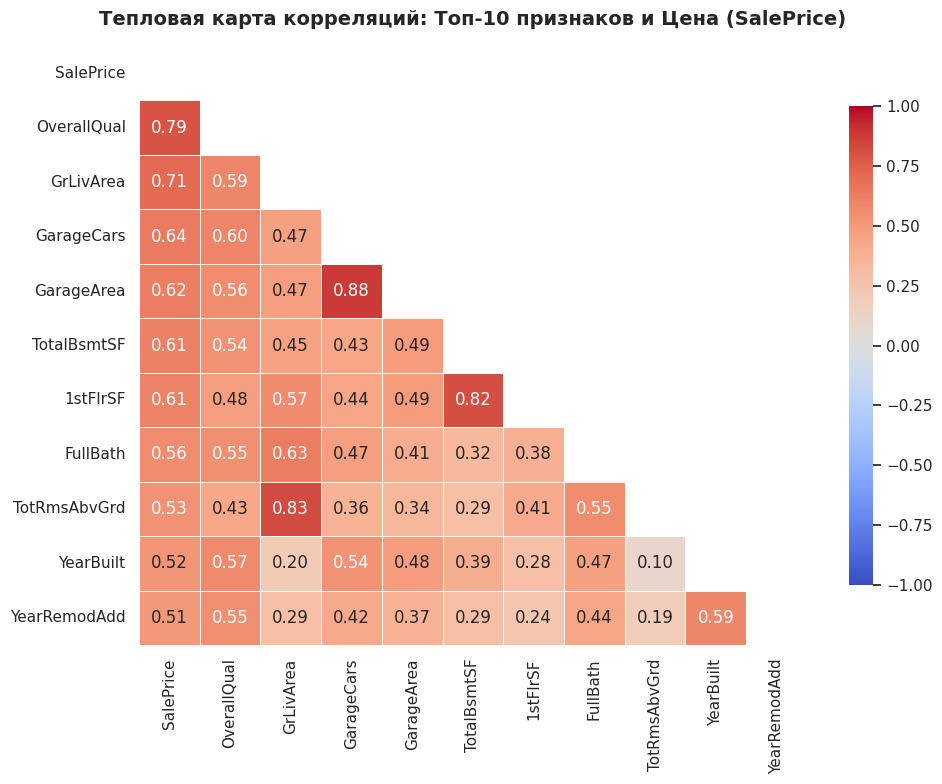


✅ Тепловая карта построена. Самые яркие квадраты в первом столбце/строке — самые важные предикторы цены.


In [20]:
# ==========================================
# Тепловая карта корреляций (Heatmap)
# ==========================================

# 1. Выбираем только числовые признаки для корреляционного анализа
numeric_df = df_clean.select_dtypes(include=['number'])

# 2. Вычисляем матрицу корреляций
corr_matrix = numeric_df.corr()

# 3. Выбираем топ-10 признаков, наиболее сильно коррелирующих с SalePrice
# (абсолютное значение корреляции, чтобы учесть и отрицательные связи, если они есть)
top_corr_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(11).index

# 4. Фильтруем матрицу корреляций только для этих топ-признаков
corr_matrix_top = corr_matrix.loc[top_corr_features, top_corr_features]

# 5. Настраиваем визуализацию
plt.figure(figsize=(10, 8))
sns.set_theme(style="white")

# Строим heatmap с аннотациями (числами) и маской для красоты (треугольник)
mask = np.triu(np.ones_like(corr_matrix_top, dtype=bool))
sns.heatmap(
    corr_matrix_top,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    mask=mask,
    linewidths=0.5,
    cbar_kws={"shrink": .8},
    vmin=-1, vmax=1
)

plt.title('Тепловая карта корреляций: Топ-10 признаков и Цена (SalePrice)',
          fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print("\n✅ Тепловая карта построена. Самые яркие квадраты в первом столбце/строке — самые важные предикторы цены.")

=== ЭТАП 5: МОДЕЛИ МАШИННОГО ОБУЧЕНИЯ ===

1. ПОДГОТОВКА ДАННЫХ
   Признаки: ['OverallQual', 'GrLivArea', 'GarageCars', 'YearBuilt', 'TotalBsmtSF', 'Neighborhood']
   Целевая переменная: SalePrice
   После кодирования: 29 признаков
   Обучающая выборка: 1168 записей
   Тестовая выборка: 292 записей

2. ОБУЧЕНИЕ И ОЦЕНКА МОДЕЛЕЙ
✅ Linear Regression (Baseline)
   MAE = $22,339
   R² = 0.8267

✅ Random Forest
   MAE = $18,264
   R² = 0.8966

✅ Hist Gradient Boosting
   MAE = $18,805
   R² = 0.8736

3. СРАВНИТЕЛЬНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ


,Модель,MAE ($),R²
0,Random Forest,18264.000000,0.896600
1,Hist Gradient Boosting,18805.000000,0.873600
2,Linear Regression (Baseline),22339.000000,0.826700


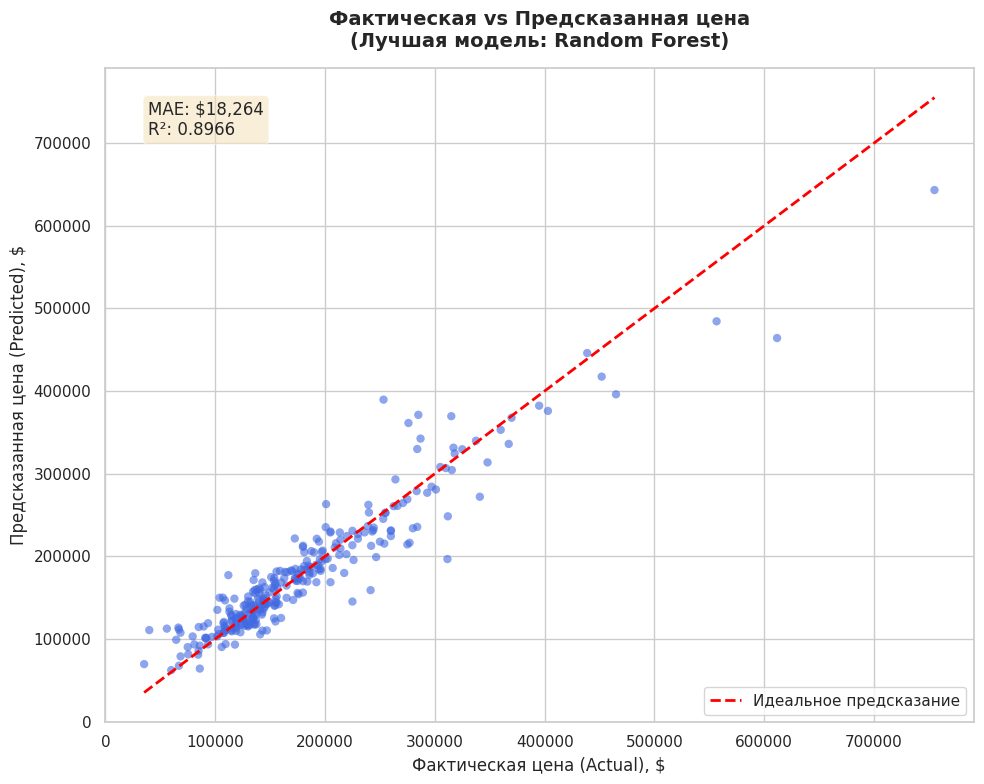


4. ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ
Лучшая модель: Random Forest
MAE: $18,264 — в среднем модель ошибается на эту сумму
R²: 0.8966 — модель объясняет 89.7% вариации цен

Вывод: Модель показывает хорошее качество

5. ПРОВЕРКА НА ПЕРЕОБУЧЕНИЕ

Linear Regression (Baseline):
  R² (train): 0.8023
  R² (test):  0.8267
  Разница:    -0.0244
  ✅ Переобучение отсутствует

Random Forest:
  R² (train): 0.9762
  R² (test):  0.8966
  Разница:    0.0795
  ✅ Переобучение отсутствует

Hist Gradient Boosting:
  R² (train): 0.9403
  R² (test):  0.8736
  Разница:    0.0667
  ✅ Переобучение отсутствует


In [26]:
# ЭТАП 5: МОДЕЛИ МАШИННОГО ОБУЧЕНИЯ
# Прогнозирование стоимости жилья (регрессия)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("=== ЭТАП 5: МОДЕЛИ МАШИННОГО ОБУЧЕНИЯ ===")


# 1. ВЫБОР ПРИЗНАКОВ (Feature Selection)
# Используем топ-наиболее информативных признаков на основе EDA
features_to_use = ['OverallQual', 'GrLivArea', 'GarageCars', 'YearBuilt',
                   'TotalBsmtSF', 'Neighborhood']
target = 'SalePrice'

# Создаём копию для подготовки
df_ml = df_clean[features_to_use + [target]].copy()

print(f"\n1. ПОДГОТОВКА ДАННЫХ")
print(f"   Признаки: {features_to_use}")
print(f"   Целевая переменная: {target}")

# 2. ПРЕДОБРАБОТКА (Кодирование категориальных признаков)
# One-Hot Encoding для Neighborhood
df_ml_encoded = pd.get_dummies(df_ml, columns=['Neighborhood'],
                                drop_first=True, dtype=int)

print(f"   После кодирования: {df_ml_encoded.shape[1]-1} признаков")

# 3. РАЗДЕЛЕНИЕ НА ОБУЧАЮЩУЮ И ТЕСТОВУЮ ВЫБОРКИ
X = df_ml_encoded.drop(columns=[target])
y = df_ml_encoded[target]

# Фиксируем random_state для воспроизводимости
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"   Обучающая выборка: {X_train.shape[0]} записей")
print(f"   Тестовая выборка: {X_test.shape[0]} записей")

# 4. ИНИЦИАЛИЗАЦИЯ И ОБУЧЕНИЕ МОДЕЛЕЙ
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100,
                                           random_state=42,
                                           n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42)
}

results = []

print(f"\n2. ОБУЧЕНИЕ И ОЦЕНКА МОДЕЛЕЙ")

for name, model in models.items():
    # Обучение
    model.fit(X_train, y_train)

    # Предсказание на тесте
    y_pred = model.predict(X_test)

    # Расчет метрик
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Модель": name,
        "MAE ($)": round(mae, 0),
        "R²": round(r2, 4)
    })

    print(f"✅ {name}")
    print(f"   MAE = ${mae:,.0f}")
    print(f"   R² = {r2:.4f}")
    print()

# 5. СРАВНИТЕЛЬНАЯ ТАБЛИЦА
results_df = pd.DataFrame(results).sort_values(by="R²", ascending=False).reset_index(drop=True)

print("3. СРАВНИТЕЛЬНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
display(results_df.style.highlight_max(subset=['R²'], color='lightgreen'))

# 6. ВИЗУАЛИЗАЦИЯ ЛУЧШЕЙ МОДЕЛИ (Actual vs Predicted)
best_model_name = results_df.iloc[0]["Модель"]
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

# Рассчитываем ошибки
errors = y_test - y_pred_best
mae_final = mean_absolute_error(y_test, y_pred_best)
r2_final = r2_score(y_test, y_pred_best)

plt.figure(figsize=(10, 8))

# Scatter plot фактических vs предсказанных цен
plt.scatter(y_test, y_pred_best, alpha=0.6, color='royalblue', edgecolor='none')

# Линия идеального предсказания (y = x)
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
plt.plot([min_val, max_val], [min_val, max_val],
         color='red', linestyle='--', linewidth=2,
         label='Идеальное предсказание')

# Добавляем статистику
plt.text(0.05, 0.95,
         f'MAE: ${mae_final:,.0f}\nR²: {r2_final:.4f}',
         transform=plt.gca().transAxes,
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.title(f'Фактическая vs Предсказанная цена\n(Лучшая модель: {best_model_name})',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Фактическая цена (Actual), $', fontsize=12)
plt.ylabel('Предсказанная цена (Predicted), $', fontsize=12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("\n4. ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ")
print(f"Лучшая модель: {best_model_name}")
print(f"MAE: ${mae_final:,.0f} — в среднем модель ошибается на эту сумму")
print(f"R²: {r2_final:.4f} — модель объясняет {r2_final*100:.1f}% вариации цен")
print(f"\nВывод: {'Модель показывает хорошее качество' if r2_final > 0.7 else 'Модель показывает удовлетворительное качество'}")

# Проверка на переобучение: сравнение R² на train и test
print("\n5. ПРОВЕРКА НА ПЕРЕОБУЧЕНИЕ")

for name, model in models.items():
    # Предсказания на обучающей выборке
    y_train_pred = model.predict(X_train)
    r2_train = r2_score(y_train, y_train_pred)

    # Предсказания на тестовой выборке (уже есть)
    y_test_pred = model.predict(X_test)
    r2_test = r2_score(y_test, y_test_pred)

    diff = r2_train - r2_test

    print(f"\n{name}:")
    print(f"  R² (train): {r2_train:.4f}")
    print(f"  R² (test):  {r2_test:.4f}")
    print(f"  Разница:    {diff:.4f}")

    if diff > 0.1:
        print(f"  ️ Возможное переобучение (разница > 0.1)")
    else:
        print(f"  ✅ Переобучение отсутствует")

=== SHAP-ИНТЕРПРЕТАЦИЯ ЛУЧШЕЙ МОДЕЛИ ===



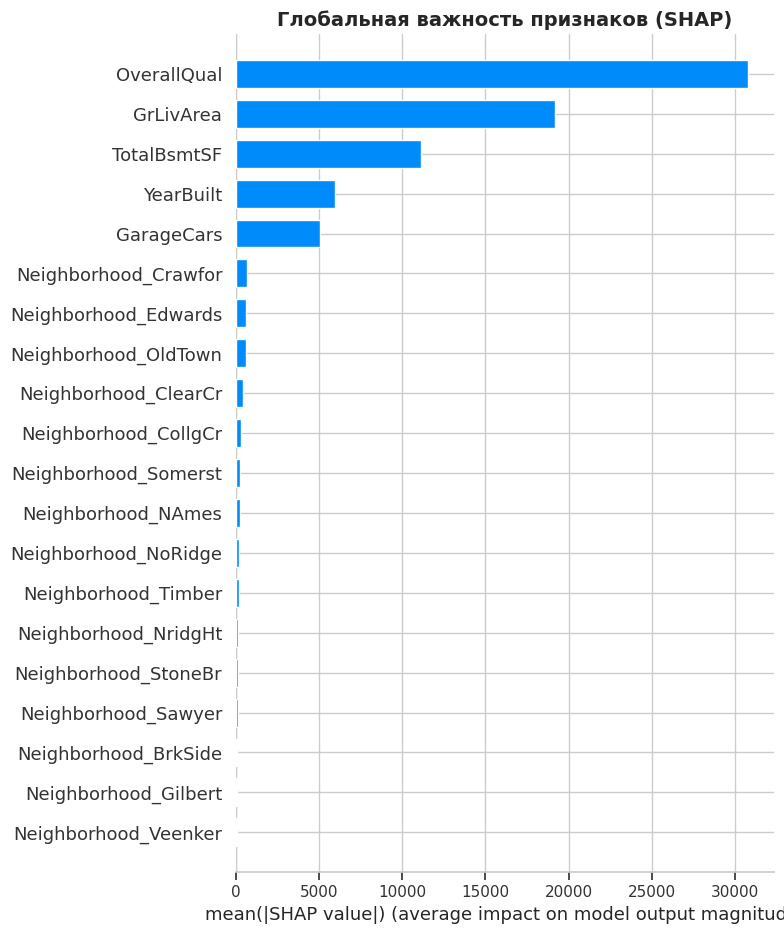

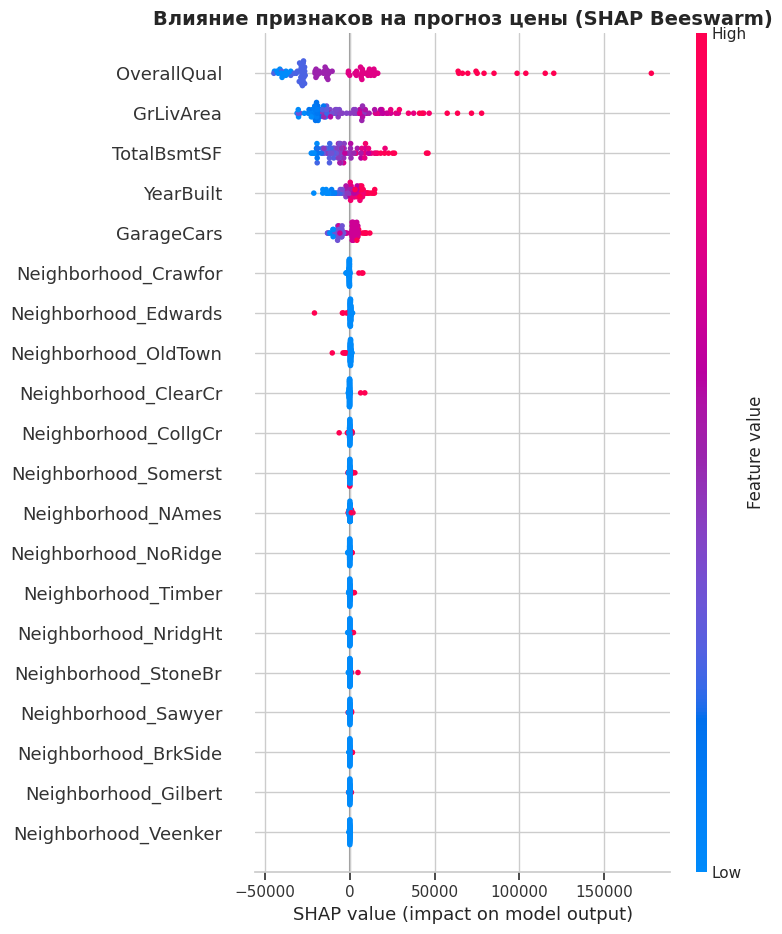


SHAP-анализ завершён ✅
   Bar plot показывает относительную важность признаков.
   Beeswarm plot показывает направление влияния (красный = повышает цену, синий = понижает).


In [22]:
# ОБЪЯСНЕНИЕ МОДЕЛИ ЧЕРЕЗ SHAP
# интерпретация прогнозов лучшей модели (Random Forest)

# Установка SHAP (в Colab не предустановлен)
!pip install shap -q

import shap

print("=== SHAP-ИНТЕРПРЕТАЦИЯ ЛУЧШЕЙ МОДЕЛИ ===\n")


# Берём лучшую модель из предыдущей ячейки
best_model = models["Random Forest"]

# Для скорости используем репрезентативную выборку из тестовых данных
X_test_sample = X_test.sample(n=100, random_state=42)


# TreeExplainer оптимизирован для ансамблей деревьев
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_sample)

# График 1: Глобальная важность признаков (bar plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", show=False)
plt.title("Глобальная важность признаков (SHAP)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# График 2: Направление и сила влияния (beeswarm plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("Влияние признаков на прогноз цены (SHAP Beeswarm)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nSHAP-анализ завершён ✅")
print("   Bar plot показывает относительную важность признаков.")
print("   Beeswarm plot показывает направление влияния (красный = повышает цену, синий = понижает).")